In [43]:
import pandas as pd
df = pd.read_csv("train.csv" , parse_dates=["date"]) # делает из текста в дату
print(df.shape, df["date"].min(), df["date"].max())
df.head()

(913000, 4) 2013-01-01 00:00:00 2017-12-31 00:00:00


,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


In [44]:
s=df[(df["store"]==1) & (df["item"] == 1)].copy()
s.head()

,date,store,item,sales
0,2013-01-01,1,1,13
1,2013-01-02,1,1,11
2,2013-01-03,1,1,14
3,2013-01-04,1,1,13
4,2013-01-05,1,1,10


<Axes: xlabel='date'>

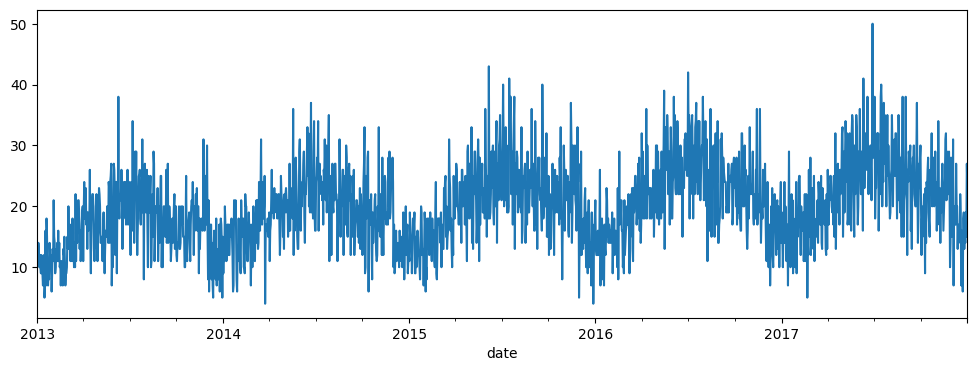

In [45]:
s.set_index("date")["sales"].plot(figsize=(12,4))


<Axes: xlabel='date'>

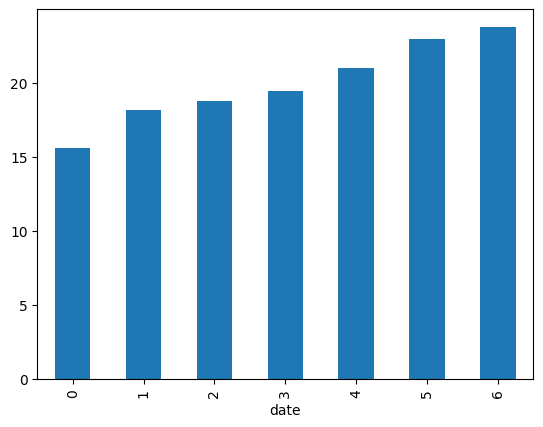

In [46]:
s.groupby(s["date"].dt.dayofweek)["sales"].mean().plot(kind="bar")  #dt открывает доступ к частям каждой даты: месяцу, году, дню недели и так далее

In [47]:
train = s[s["date"] < "2017-10-01"]
test = s[s["date"] >= "2017-10-01"]


In [48]:
from sklearn.metrics import mean_absolute_error

s["naive"] = s["sales"].shift(7)
test = s[s["date"] >= "2017-10-01"]
print(mean_absolute_error(test["sales"], test["naive"]))

s.head()

5.0978260869565215


,date,store,item,sales,naive
0,2013-01-01,1,1,13,NaN
1,2013-01-02,1,1,11,NaN
2,2013-01-03,1,1,14,NaN
3,2013-01-04,1,1,13,NaN
4,2013-01-05,1,1,10,NaN


In [49]:
from sklearn.linear_model import LinearRegression
features = ["dayofweek", "month", "year", "dayofyear"]
for col in features:
    s[col] = getattr(s["date"].dt, col)  #достаёт свойство по его имени-строке 1-й круг – s["date"].dt.dayofweek, на втором .dt.month
train = s[s["date"] <  "2017-10-01"]
test  = s[s["date"] >= "2017-10-01"]
model = LinearRegression().fit(train[features], train["sales"])
print(s.tail())
print("MAE:", mean_absolute_error(test["sales"], model.predict(test[features])))

           date  store  item  sales  naive  dayofweek  month  year  dayofyear
1821 2017-12-27      1     1     14   16.0          2     12  2017        361
1822 2017-12-28      1     1     19   12.0          3     12  2017        362
1823 2017-12-29      1     1     15    6.0          4     12  2017        363
1824 2017-12-30      1     1     27   18.0          5     12  2017        364
1825 2017-12-31      1     1     23   19.0          6     12  2017        365
MAE: 6.102962043871438


In [50]:
df = df.sort_values(["store", "item", "date"])
g = df.groupby(["store", "item"])["sales"]

df["lag_7"] = g.shift(7)
df["lag_14"] = g.shift(14)
df["rolling_mean_7"] = g.transform(
    lambda x: x.shift(1).rolling(7).mean()
)

df = df.dropna(subset=["lag_7", "lag_14", "rolling_mean_7"])

In [51]:
# Признаки из даты для всех магазинов и товаров
for col in ["dayofweek", "month", "year", "dayofyear"]:
    df[col] = getattr(df["date"].dt, col)

In [52]:
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error
date_f = ["store" , "item" , "dayofweek" , "month" , "year" , "dayofyear"]
lag_f = date_f + ["lag_7" , "lag_14" , "rolling_mean_7"]
train = df[df["date"] < "2017-10-01"] # берём столбец с датами проверяем каждую дату сохраняем строки, где получилось true
test = df[df["date"] >= "2017-10-01"]
for name , col in [("без лагов", date_f), ("с лагами", lag_f)]:
    m = LGBMRegressor(n_estimators=500, learning_rate=0.05, verbose=-1)
    m.fit(train[col], train["sales"])
    mae = mean_absolute_error(test["sales"], m.predict(test[col]))
    if name == "без лагов":
        mae_without_lags = mae
    else:
        mae_with_lags = mae
    print(name, mae)


без лагов 6.223637391387938
с лагами 6.121191088033972


In [53]:
from sklearn.model_selection import TimeSeriesSplit, cross_val_score
import numpy as np
tr = train.sort_values("date").reset_index(drop=True) #reset_index(drop=True) даёт строкам новые номера 0, 1, 2, ... drop=True отбросить старые номера
days = tr["date"].drop_duplicates().to_numpy()  #to_numpy() превращает результат в массив, который дальше передаём в TimeSeriesSplit , days - массив дат
split_by_date = []
for old, new in TimeSeriesSplit(n_splits=5).split(days): # old - позиции более ранних дат для обучения, new - позиции следующих дат для проверки первом проходе получится older = [0], newer = [1]. Значит, учимся на 1 января, проверяем на 2 января. На втором проходе получится older = [0, 1], newer = [2]: учимся на 1 и 2 января, проверяем на 3 января.
    #находим строки для обучения 
    train_dates = days[old]                # Берём дату на позиции 0 → 1 января
    mask = tr["date"].isin(train_dates)      # Проверяем дату каждой строки таблицы
    train_rows = np.flatnonzero(mask)        # Собираем позиции, где получилось True  np.flatnonzero() возвращает позиции этих двух True. Получаем train_rows = [0, 1]
    #Находим строки для проверки
    valid_rows = np.flatnonzero(tr["date"].isin(days[new]))
    split_by_date.append((train_rows, valid_rows)) #собирает одну пару [1,2] и добавляет в список
scores = cross_val_score(#В scores сохраняются пять оценок, по одной за каждую проверку
                            #cross_val_score() — функция, которая несколько раз обучает и проверяет модель на разных частях данных и возвращает оценку за каждую проверку 
                            # cross_val_score() Обучает новую модель на строках train_rows, используя признаки и реальные продажи. Прогнозирует продажи для строк valid_rows. Считает ошибку, сравнивая прогнозы с реальными продажами в valid_rows
    LGBMRegressor(n_estimators=500, learning_rate=0.05, verbose=-1),
    tr[lag_f], tr["sales"], cv=split_by_date, #tr[lag_f] и tr["sales"] задают входы и правильные ответы tr[lag_f] выбирает из таблицы tr все столбцы, которые модель получит на вход: магазин, товар, признаки из даты, продажи неделю и две недели назад и скользящее среднее.
    scoring="neg_mean_absolute_error"
    
)
print(-scores.mean())                  # минус возвращает обычный MAE  )

6.052019165470786


In [ ]:
# baseline
naive_mae = mean_absolute_error(test["sales"], test["lag_7"])

# Линейная регрессия без лагов
linear = LinearRegression()
linear.fit(train[date_f], train["sales"])
linear_predictions = linear.predict(test[date_f])
linear_mae = mean_absolute_error(test["sales"], linear_predictions)

print(f"Baseline: {naive_mae:.2f}")
print(f"Линейная регрессия: {linear_mae:.2f}")
print(f"Бустинг без лагов: {mae_without_lags:.2f}")
print(f"Бустинг с лагами: {mae_with_lags:.2f}")


Baseline: 9.08
Линейная регрессия: 25.22
Бустинг без лагов: 6.22
Бустинг с лагами: 6.12


по сравнению с наивным прогнозом основной прирост дал бустинг без лагов: MAE снизился с 9,08 до 6,22, а добавление лагов снизило его ещё на 0,10 .